# How Much Can a University Spend? Endowment Spending Rules Tested on Two Decades of IPEDS Finance Data, the Rule Endowments Actually Follow, and a Simulation of Intergenerational Equity since 1928

A university endowment is meant to last forever. Each year the board decides how much of it to spend on scholarships, professorships and research. Spend too much and future students inherit a smaller fund; spend too little and today's students pay for a wealth they never use. Most U.S. endowments solve the problem with a **spending rule**: a fixed percentage of a moving average of past market values, sometimes blended with last year's spending adjusted for inflation. This notebook measures the market, finds the rule endowments actually follow in their own reported numbers, and tests the common rules against almost a century of market history.

**What it does.**

1. It reads the endowment section of the IPEDS finance survey for every U.S. college and university, fiscal years 2005 to 2023: the endowment's value at the start and end of each year and, from 2020, what moved it (new gifts, investment return, spending and other changes).
2. It describes the market: total assets of private and public endowments, their concentration, and returns and spending rates by size from 2020 to 2023.
3. It finds the **revealed spending rule**. It compares spending with the beginning value and with the trailing three-year average, and estimates how much weight institutions put on last year's spending versus the market value.
4. It predicts each institution's 2023 spending out of time with the revealed rule, its own past rate, ridge regression and LightGBM.
5. It simulates 50 years of an endowment invested in a diversified portfolio, using block-bootstrapped annual market returns and inflation since 1928. It compares five rules on spending stability and on preserving the endowment's real value, searches for the best smoothing weight and spending rate, and replays three historical starting years.

**Data.** IPEDS finance survey, endowment section of forms F1A (public, GASB) and F2 (private not-for-profit, FASB), and institutional characteristics (National Center for Education Statistics); annual returns on U.S. stocks, Treasury and Baa corporate bonds and real estate since 1928 (Damodaran Online); consumer price index (FRED).

**Methods.** Endowment flow decomposition, spending rates on beginning and trailing-average values, robust regression of the spending rule, out-of-time prediction with ridge regression and LightGBM, block-bootstrap Monte Carlo of asset returns and inflation, five spending rules, grid search of smoothing weight and spending rate, and historical replays.

**Key output.** The size and concentration of U.S. endowments; returns and spending rates by size; the revealed spending rule; the accuracy of the spending forecasts; and the trade-off between stable spending and preserved purchasing power for each rule.

## 1. Spending rules and intergenerational equity

**Intergenerational equity.** Tobin (1974) defined the goal of an endowment's trustees as preserving equity among generations: the endowment should support the same real activity in the future as today. That requires spending, on average, no more than the expected real return net of costs. With a real return of 4–5%, that is why most rules aim at 4–5% a year.

**The rules.** With *M* the endowment's market value, *S* spending and *π* inflation:
- **Fixed percentage of the current value:** *S*ₜ = *r* × *M*ₜ. It is simple and preserves value, but spending swings with markets.
- **Moving average:** *S*ₜ = *r* × average(*M*ₜ₋₁, *M*ₜ₋₂, *M*ₜ₋₃). The most common rule in the U.S.; it spreads a market fall over three years.
- **Hybrid (inflation-linked smoothing),** used by Yale and Stanford: *S*ₜ = *w* × *S*ₜ₋₁ × (1 + *π*ₜ) + (1 − *w*) × *r* × *M*ₜ₋₁. With *w* = 0.8, last year's real spending gets 80% of the weight, so spending is very stable but adjusts slowly to markets.
- **Constant real spending:** *S*ₜ = *S*₀ × prices. Perfectly stable, but nothing stops the endowment from running down after poor returns.

**Law.** The Uniform Prudent Management of Institutional Funds Act (UPMIFA), adopted by almost every state, presumes that spending above 7% of a fund's value, averaged over at least three years, is imprudent.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile

import lightgbm as lgb
from sklearn.linear_model import HuberRegressor, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 1974
rng = np.random.default_rng(SEED)
# IPEDS finance files F0405 … F2223 (fiscal year ends mid-calendar-year)
FISCAL_YEARS = range(2005, 2024)
IPEDS_URL = "https://nces.ed.gov/ipeds/datacenter/data/"
DAMODARAN_URL = (
    "https://pages.stern.nyu.edu/~adamodar/pc/datasets/histretSP.xls"
)
WEIGHTS = {
    "S&P 500": 0.60,
    "Baa corporate bond": 0.20,
    "10-year Treasury": 0.10,
    "real estate": 0.10,
}
TARGET_RATE, HORIZON, N_PATHS, BLOCK = 0.045, 50, 5000, 5

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-03


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. The data: twenty years of endowments

IPEDS publishes one finance file per fiscal year and form: F1A for public institutions that report under GASB standards and F2 for private not-for-profit institutions under FASB. The notebook looks for the zipped files in `data/ipeds_finance/` at the root of the repository and downloads any missing file from the NCES data center. When a revised file (`_rv`) is available it is used instead of the original. Public and private status comes from the institutional characteristics file, because some public institutions report on the FASB form; the few for-profit institutions are left out.

Section H of each form reports the endowment's value at the start and end of the fiscal year. From fiscal year 2020 it also reports the change in four parts: new gifts, net investment return, spending distributions for current use, and other changes.

In [3]:
def find_shared(name):
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
    return None


IPEDS_DIR = find_shared("ipeds_finance") or (
    PROJECT_DIR.parents[1] / "data" / "ipeds_finance"
)
IPEDS_DIR.mkdir(parents=True, exist_ok=True)


def ipeds_zip(name):
    p = IPEDS_DIR / f"{name}.zip"
    if not p.exists():
        r = requests.get(
            IPEDS_URL + p.name,
            timeout=120,
            headers={"User-Agent": "Mozilla/5.0"},
        )
        r.raise_for_status()
        p.write_bytes(r.content)
    return p


def read_ipeds(name):
    with zipfile.ZipFile(ipeds_zip(name)) as z:
        files = sorted(n for n in z.namelist() if n.lower().endswith(".csv"))
        pick = next(
            (n for n in files if n.lower().endswith("_rv.csv")), files[0]
        )
        d = pd.read_csv(z.open(pick), encoding="latin-1", low_memory=False)
    d.columns = d.columns.str.strip().str.upper()
    return d


FIELDS = {
    "H01": "mv_begin",
    "H02": "mv_end",
    "H03A": "gifts",
    "H03B": "inv_return",
    "H03C": "spending",
    "H03D": "other",
}


def load_panel():
    rows = []
    for fy in FISCAL_YEARS:
        tag = f"F{(fy - 1) % 100:02d}{fy % 100:02d}"
        for form, sector in [("F2", "private"), ("F1A", "public")]:
            d = read_ipeds(f"{tag}_{form}")
            pre = "F2" if form == "F2" else "F1"
            cols = {pre + k: v for k, v in FIELDS.items() if pre + k in d}
            x = d[["UNITID", *cols]].rename(columns=cols)
            for c in cols.values():
                x[c] = pd.to_numeric(
                    x[c].astype(str).str.strip(), errors="coerce"
                )
            rows.append(x.assign(fy=fy, sector=sector))
    return pd.concat(rows, ignore_index=True)


E = cached("ipeds_endowments_2005_2023", load_panel, max_age_hours=24 * 365)
E = E[E["mv_end"] > 0].sort_values(["UNITID", "fy"]).reset_index(drop=True)
HD = read_ipeds("HD2022")[["UNITID", "INSTNM", "STABBR", "CONTROL"]]
E = E.merge(HD, on="UNITID", how="left")
# some public institutions file the FASB form
E["sector"] = E["CONTROL"].map({1: "public", 2: "private"}).fillna(E["sector"])
# for-profit institutions
E = E[E["CONTROL"].ne(3)].drop(columns="CONTROL")
E["spend"] = -E["spending"]

size = E.groupby(["fy", "sector"])["mv_end"].agg(["size", "sum"]).unstack()
MARKET = pd.DataFrame({
    "institutions": size["size"].sum(axis=1),
    "private ($bn)": size["sum"]["private"] / 1e9,
    "public ($bn)": size["sum"]["public"] / 1e9,
})
MARKET["total ($bn)"] = MARKET["private ($bn)"] + MARKET["public ($bn)"]
top20 = E.groupby("fy")["mv_end"].apply(
    lambda s: s.nlargest(20).sum() / s.sum()
)
MARKET["top-20 share"] = top20
last = E[E["fy"] == E["fy"].max()].nlargest(10, "mv_end")[
    ["INSTNM", "sector", "mv_end"]
]
print(
    f"{E['UNITID'].nunique():,} institutions; fiscal {E['fy'].max()}:"
    f" ${MARKET['total ($bn)'].iloc[-1]:,.0f}bn in"
    f" {MARKET['institutions'].iloc[-1]:,.0f} endowments, top 20 hold"
    f" {MARKET['top-20 share'].iloc[-1]:.0%}"
)
display(
    last.assign(mv_end=last["mv_end"] / 1e9)
    .rename(columns={"mv_end": "endowment ($bn)"})
    .style.format({"endowment ($bn)": "{:,.1f}"})
    .hide(axis="index")
)
MARKET.loc[
    [2005, 2008, 2009, 2013, 2019, 2020, 2021, 2022, 2023]
].style.format({
    "institutions": "{:,.0f}",
    "private ($bn)": "{:,.0f}",
    "public ($bn)": "{:,.0f}",
    "total ($bn)": "{:,.0f}",
    "top-20 share": "{:.0%}",
})

3,062 institutions; fiscal 2023: $913bn in 2,645 endowments, top 20 hold 46%


INSTNM,sector,endowment ($bn)
Harvard University,private,50.7
The University of Texas System Office,public,43.9
Yale University,private,40.7
Stanford University,private,36.5
Princeton University,private,33.4
Massachusetts Institute of Technology,private,23.5
University of Pennsylvania,private,21.0
Texas A & M University-College Station,public,18.1
University of California-System Administration Central Office,public,17.9
University of Michigan-Ann Arbor,public,17.6


,institutions,private ($bn),public ($bn),total ($bn),top-20 share
fy,,,,,
2005,"2,528",228,71,299,46%
2008,"2,625",312,104,416,47%
2009,"2,613",239,89,328,46%
2013,"2,652",327,143,470,45%
2019,"2,694",460,220,680,45%
2020,"2,693",470,226,696,45%
2021,"2,689",634,299,933,46%
2022,"2,662",599,293,892,47%
2023,"2,645",603,310,913,46%


## 4. Returns and spending, 2020–2023

From fiscal 2020 the flows show what each endowment earned and spent. The **spending rate** is measured two ways: on the value at the start of the year, and on the average of the three previous year-end values, the base most rules use. Institutions are grouped by the size of their endowment at the start of the year; endowments under \$10 million are left out, because a single gift or transfer can dominate them.

In [4]:
g = E.groupby("UNITID")
for k in (1, 2, 3):
    E[f"mv_lag{k}"] = g["mv_end"].shift(k)
E["avg3"] = E[["mv_lag1", "mv_lag2", "mv_lag3"]].mean(axis=1, skipna=False)
E["spend_lag"] = g["spend"].shift(1)
F = E[(E["fy"] >= 2020) & (E["mv_begin"] > 10e6) & (E["spend"] > 0)].copy()
F["rate on beginning value"] = F["spend"] / F["mv_begin"]
F["rate on 3-year average"] = F["spend"] / F["avg3"]
F["return"] = F["inv_return"] / F["mv_begin"]
F["gifts rate"] = F["gifts"] / F["mv_begin"]
F["size"] = pd.cut(
    F["mv_begin"],
    [10e6, 100e6, 1e9, np.inf],
    labels=["$10m–100m", "$100m–1bn", "over $1bn"],
)
F = F[F["return"].between(-0.6, 1.0) & F["rate on beginning value"].lt(0.3)]
cols = [
    "return",
    "rate on beginning value",
    "rate on 3-year average",
    "gifts rate",
]
BY_YEAR = F.groupby("fy")[cols].median()
BY_SIZE = (
    F.groupby(["fy", "size"], observed=True)[
        ["return", "rate on beginning value"]
    ]
    .median()
    .unstack()
)
print(
    f"{len(F):,} institution-years from {F['UNITID'].nunique():,}"
    " institutions; spending above 7% of the beginning value:"
    f" {(F['rate on beginning value'] > 0.07).mean():.0%}"
)
display(BY_YEAR.style.format("{:.1%}"))
BY_SIZE.style.format("{:.1%}")

5,671 institution-years from 1,654 institutions; spending above 7% of the beginning value: 10%


,return,rate on beginning value,rate on 3-year average,gifts rate
fy,,,,
2020,2.0%,4.3%,4.5%,2.3%
2021,27.5%,4.3%,4.4%,2.6%
2022,-8.6%,3.7%,4.3%,2.6%
2023,7.1%,4.3%,4.5%,2.3%


## 5. The revealed spending rule

If an institution follows a hybrid rule, this year's spending is a weighted average of last year's spending grown with inflation and a spending rate times the market value:

*S*ₜ = *w* × *S*ₜ₋₁ × (1 + *π*ₜ) + (1 − *w*) × *r* × *M̄*ₜ,

where *M̄* is the three-year average value. Dividing by the beginning value turns this into a regression without intercept on two terms. The coefficients give the smoothing weight *w* and the long-run spending rate *r*. A robust (Huber) regression limits the influence of institutions with unusual transfers. Inflation is the change in the CPI over the fiscal year to June.

In [5]:
CPI = fred.get_series("CPIAUCNS").resample("ME").last()
jun = CPI[CPI.index.month == 6]
INFL_FY = (jun / jun.shift(1) - 1).rename(index=lambda t: t.year)
R = F.dropna(subset=["spend_lag", "avg3"]).copy()
R["infl"] = R["fy"].map(INFL_FY)
R["x_last"] = R["spend_lag"] * (1 + R["infl"]) / R["mv_begin"]
R["x_avg"] = R["avg3"] / R["mv_begin"]
R["y"] = R["spend"] / R["mv_begin"]
R = R[R["x_last"].lt(0.3) & R["x_avg"].between(0.3, 3)]


def revealed(d):
    m = HuberRegressor(fit_intercept=False, epsilon=1.35, max_iter=500).fit(
        d[["x_last", "x_avg"]], d["y"]
    )
    w, b = m.coef_
    return pd.Series({
        "observations": len(d),
        "smoothing weight w": w,
        "spending rate r": b / (1 - w) if w < 1 else np.nan,
    })


REVEALED = pd.DataFrame({
    "all years": revealed(R),
    **{str(y): revealed(R[R["fy"] == y]) for y in sorted(R["fy"].unique())},
    "private": revealed(R[R["sector"] == "private"]),
    "public": revealed(R[R["sector"] == "public"]),
    "over $1bn": revealed(R[R["size"] == "over $1bn"]),
}).T
W_REV, R_REV = REVEALED.loc[
    "all years", ["smoothing weight w", "spending rate r"]
]
RG = R[R["spend_lag"] > 0]
growth = (
    RG.assign(
        real_growth=np.log(RG["spend"] / RG["spend_lag"])
        - np.log1p(RG["infl"])
    )
    .groupby("fy")[["real_growth", "return"]]
    .median()
)
print(f"pooled revealed rule: w = {W_REV:.2f}, r = {R_REV:.2%}")
display(growth.style.format("{:+.1%}"))
REVEALED.style.format({
    "observations": "{:,.0f}",
    "smoothing weight w": "{:.2f}",
    "spending rate r": "{:.2%}",
})

pooled revealed rule: w = 0.32, r = 4.53%


,real_growth,return
fy,,
2021,-1.6%,+27.6%
2022,-1.9%,-8.5%
2023,+6.3%,+7.1%


,observations,smoothing weight w,spending rate r
all years,"4,361",0.32,4.53%
2021,"1,251",0.34,4.41%
2022,"1,566",0.10,4.41%
2023,"1,544",0.86,6.06%
private,"2,613",0.28,4.69%
public,"1,748",0.35,4.24%
over $1bn,364,0.79,4.79%


## 6. Predicting next year's spending

A finance office plans next year's budget before the year's spending is set. Trained on fiscal 2021 and 2022 and tested on 2023, which models predict each institution's spending rate on its beginning value best?
- **Revealed rule:** the median 2021–2022 rate on the three-year average, times the institution's three-year average.
- **Own last rate:** last year's spending grown with inflation.
- **Ridge regression and LightGBM** on the institution's last spending rate, its three-year average relative to the beginning value, its last two returns, size, sector and the gifts rate.

In [6]:
E["ret"] = E["inv_return"] / E["mv_begin"]
E["ret_lag1"] = E.groupby("UNITID")["ret"].shift(1)
M = R.merge(E[["UNITID", "fy", "ret_lag1"]], on=["UNITID", "fy"], how="left")
M["last rate"] = M["spend_lag"] / M["mv_begin"]
M["log size"] = np.log(M["mv_begin"])
M["private"] = (M["sector"] == "private").astype(int)
M["mv_lag1 / begin"] = M["mv_lag1"] / M["mv_begin"]
FEATS = [
    "last rate",
    "x_last",
    "x_avg",
    "mv_lag1 / begin",
    "ret_lag1",
    "log size",
    "private",
    "gifts rate",
    "infl",
]
tr, te = M["fy"].isin([2021, 2022]).to_numpy(), (M["fy"] == 2023).to_numpy()
fill = M.loc[tr, FEATS].median()
ridge = RidgeCV(alphas=np.logspace(-4, 2, 13)).fit(
    M.loc[tr, FEATS].fillna(fill), M.loc[tr, "y"]
)
gbm = lgb.LGBMRegressor(
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    random_state=SEED,
    verbose=-1,
).fit(M.loc[tr, FEATS], M.loc[tr, "y"])
base_rate = (M.loc[tr, "spend"] / M.loc[tr, "avg3"]).median()
preds = {
    "revealed rule (rate × 3-year average)": base_rate * M.loc[te, "x_avg"],
    "own last rate, grown with inflation": M.loc[te, "x_last"],
    "ridge regression": ridge.predict(M.loc[te, FEATS].fillna(fill)),
    "LightGBM": gbm.predict(M.loc[te, FEATS]),
}
y_te = M.loc[te, "y"]
FORECAST = pd.DataFrame({
    k: {
        "MAE (pp)": mean_absolute_error(y_te, v) * 100,
        "R²": r2_score(y_te, v),
        "within 0.5 pp": (np.abs(y_te - v) < 0.005).mean(),
    }
    for k, v in preds.items()
}).T
print(
    f"train {tr.sum():,} institution-years (2021–2022), test {te.sum():,}"
    " (2023)"
)
FORECAST.style.format(
    {"MAE (pp)": "{:.2f}", "R²": "{:.2f}", "within 0.5 pp": "{:.0%}"}
)

train 2,817 institution-years (2021–2022), test 1,544 (2023)


,MAE (pp),R²,within 0.5 pp
revealed rule (rate × 3-year average),1.83,-0.00,31%
"own last rate, grown with inflation",1.36,0.22,53%
ridge regression,1.56,0.25,35%
LightGBM,1.42,0.26,44%


## 7. Fifty years of spending: a simulation since 1928

**Returns.** Annual returns on the S&P 500 with dividends, Baa corporate bonds, 10-year Treasuries and real estate from 1928, and CPI inflation for the same calendar years. The endowment holds 60% stocks, 20% corporate bonds, 10% Treasuries and 10% real estate, rebalanced each year, and pays 0.5% a year in costs. Large endowments also hold private equity, hedge funds and real assets, which these indices do not capture.

**Scenarios.** 5,000 paths of 50 years are drawn by resampling blocks of five consecutive years, so each path keeps the joint behaviour of returns and inflation within a block (for example, high inflation with poor bond returns in the 1970s). Every rule starts from the same endowment of 100 and spends 4.5% in the first year. New gifts are left out, so the test is whether the existing endowment keeps its purchasing power.

**Measures.**
- **Average real spending** over 50 years, per 100 of the starting endowment (in today's prices). The first year's spending is 4.5.
- **Volatility of real spending:** the standard deviation of annual changes in real spending.
- **Real cuts:** the share of years in which real spending falls by more than 10%.
- **Erosion:** the probability that the endowment's real value after 50 years is below its starting value, which breaks intergenerational equity.

In [7]:
def fetch_damodaran():
    r = requests.get(
        DAMODARAN_URL, timeout=120, headers={"User-Agent": "Mozilla/5.0"}
    )
    r.raise_for_status()
    d = pd.read_excel(
        io.BytesIO(r.content),
        "Returns by year",
        header=None,
        skiprows=19,
        usecols=range(8),
    )
    d.columns = [
        "year",
        "S&P 500",
        "small cap",
        "3-month T-bill",
        "10-year Treasury",
        "Baa corporate bond",
        "real estate",
        "gold",
    ]
    d = d[
        pd.to_numeric(d["year"], errors="coerce").between(1928, 2100)
    ].astype(float)
    return d.set_index(d["year"].astype(int)).drop(columns="year")


H = cached("damodaran_annual_returns", fetch_damodaran, max_age_hours=24 * 90)
H.index = H.index.astype(int)
dec = CPI[CPI.index.month == 12]
H["inflation"] = (
    (dec / dec.shift(1) - 1).rename(index=lambda t: t.year).reindex(H.index)
)
H = H.dropna(subset=["inflation"])
H["portfolio"] = sum(w * H[k] for k, w in WEIGHTS.items()) - 0.005
print(
    f"history {H.index.min()}–{H.index.max()}: portfolio"
    f" {H['portfolio'].mean():.1%} nominal,"
    f" {((1 + H['portfolio']) / (1 + H['inflation']) - 1).mean():.1%} real a"
    " year on average"
)


def draw_paths(n=N_PATHS, horizon=HORIZON, block=BLOCK):
    years = H.index.to_numpy()
    starts = rng.integers(
        0, len(years) - block + 1, size=(n, int(np.ceil(horizon / block)))
    )
    idx = (starts[:, :, None] + np.arange(block)).reshape(n, -1)[:, :horizon]
    return H["portfolio"].to_numpy()[idx], H["inflation"].to_numpy()[idx]


RET, INF = draw_paths()


def simulate(rule, ret, inf, rate=TARGET_RATE, w=0.0):
    """
    Real spending and real value paths for one rule. Spending is paid at the
    start of each year.
    """
    n, T = ret.shape
    mv, price = np.full(n, 100.0), np.ones(n)
    # three previous year-end values
    hist = [np.full(n, 100.0)] * 3
    s_prev = np.full(n, rate * 100.0)
    spend, value = np.zeros((n, T)), np.zeros((n, T))
    for t in range(T):
        avg3 = np.mean(hist[-3:], axis=0)
        if rule == "fixed % of value":
            s = rate * mv
        elif rule == "3-year average":
            s = rate * avg3
        elif rule == "constant real":
            s = rate * 100.0 * price
        else:  # hybrid
            s = (
                s_prev * (1 + (inf[:, t - 1] if t else 0)) * w
                + (1 - w) * rate * avg3
                if t
                else np.full(n, rate * 100.0)
            )
        s = np.minimum(np.maximum(s, 0), mv)
        mv = (mv - s) * (1 + ret[:, t])
        price = price * (1 + inf[:, t])
        spend[:, t], value[:, t] = s / (price / (1 + inf[:, t])), mv / price
        hist.append(mv)
        s_prev = s
    return spend, value


def measures(spend, value):
    prev = spend[:, :-1]
    # undefined once the fund is empty
    chg = np.where(
        prev > 0, spend[:, 1:] / np.where(prev > 0, prev, 1) - 1, np.nan
    )
    return {
        "average real spending": spend.mean(),
        "volatility of real spending": np.nanstd(chg),
        "years with a real cut > 10%": np.nanmean(chg < -0.10),
        "P(fund exhausted)": (value[:, -1] <= 1e-6).mean(),
        "P(real value after 50y < start)": (value[:, -1] < 100).mean(),
        "median real value after 50y": np.median(value[:, -1]),
    }


RULES = {
    "fixed % of value": {},
    "3-year average": {},
    "hybrid, w = 0.8 (Yale-type)": {"w": 0.8},
    f"hybrid, revealed w = {W_REV:.2f}": {"w": float(np.clip(W_REV, 0, 0.95))},
    "constant real": {},
}
SIM = {}
for name, kw in RULES.items():
    rule = "hybrid" if name.startswith("hybrid") else name
    SIM[name] = simulate(rule, RET, INF, **kw)
RULE_TABLE = pd.DataFrame({k: measures(*v) for k, v in SIM.items()}).T
RULE_TABLE.style.format({
    "average real spending": "{:.2f}",
    "P(fund exhausted)": "{:.0%}",
    "volatility of real spending": "{:.1%}",
    "years with a real cut > 10%": "{:.1%}",
    "P(real value after 50y < start)": "{:.0%}",
    "median real value after 50y": "{:.0f}",
})

history 1928–2025: portfolio 8.9% nominal, 5.8% real a year on average


,average real spending,volatility of real spending,years with a real cut > 10%,P(fund exhausted),P(real value after 50y < start),median real value after 50y
fixed % of value,5.58,12.0%,17.1%,0%,43%,115
3-year average,5.61,7.1%,8.5%,0%,40%,123
"hybrid, w = 0.8 (Yale-type)",5.58,3.7%,0.1%,0%,43%,120
"hybrid, revealed w = 0.32",5.61,6.1%,5.5%,0%,40%,122
constant real,3.94,10.2%,1.3%,35%,48%,124


### Searching for the best hybrid rule

A grid of smoothing weights (0 to 0.9) and spending rates (3% to 6%) is simulated on the first 2,000 paths. The board's problem is framed as: spend as much as possible on average, per 100 of today's endowment, subject to keeping the probability of real erosion after 50 years at or below 50% (intergenerational equity in the median) and the share of years with a real cut above 10% at or below 5%.

In [8]:
grid = []
for w in np.round(np.arange(0, 0.95, 0.1), 2):
    for r in np.round(np.arange(0.030, 0.0601, 0.0025), 4):
        sp, va = simulate("hybrid", RET[:2000], INF[:2000], rate=r, w=w)
        grid.append({"w": w, "rate": r, **measures(sp, va)})
GRID = pd.DataFrame(grid)
ok = GRID[
    (GRID["P(real value after 50y < start)"] <= 0.5)
    & (GRID["years with a real cut > 10%"] <= 0.05)
]
BEST = (
    ok.loc[ok["average real spending"].idxmax()] if len(ok) else GRID.iloc[0]
)
print(
    f"best feasible hybrid: w = {BEST['w']:.1f}, rate = {BEST['rate']:.2%};"
    f" average real spending {BEST['average real spending']:.2f}, erosion"
    f" probability {BEST['P(real value after 50y < start)']:.0%}, real cuts in"
    f" {BEST['years with a real cut > 10%']:.1%} of years"
)
GRID.pivot(
    index="w", columns="rate", values="P(real value after 50y < start)"
).style.format("{:.0%}").background_gradient(cmap="RdYlGn_r", axis=None)

best feasible hybrid: w = 0.3, rate = 3.50%; average real spending 5.71, erosion probability 19%, real cuts in 4.6% of years


rate,0.030000,0.032500,0.035000,0.037500,0.040000,0.042500,0.045000,0.047500,0.050000,0.052500,0.055000,0.057500,0.060000
w,,,,,,,,,,,,,
0.000000,11%,14%,19%,23%,28%,34%,41%,48%,55%,61%,68%,73%,79%
0.100000,11%,14%,19%,23%,28%,34%,41%,48%,55%,62%,68%,73%,79%
0.200000,11%,14%,19%,23%,28%,34%,41%,48%,55%,62%,68%,73%,79%
0.300000,11%,14%,19%,23%,28%,35%,41%,48%,55%,62%,68%,73%,79%
0.400000,11%,15%,19%,23%,29%,35%,41%,48%,55%,62%,68%,74%,79%
0.500000,11%,15%,19%,23%,29%,35%,41%,48%,56%,62%,69%,74%,80%
0.600000,11%,15%,19%,23%,29%,36%,42%,48%,56%,63%,69%,74%,80%
0.700000,11%,15%,20%,24%,30%,36%,43%,49%,57%,64%,70%,75%,80%
0.800000,12%,16%,20%,25%,31%,37%,44%,50%,58%,65%,71%,77%,81%


### Three historical starting points

The same rules applied to the actual sequence of returns and inflation from three starting years: 1929 (the Depression), 1966 (the start of the high-inflation years) and 2000 (two equity crashes in a decade). Each replay runs to the end of the data or 50 years, whichever comes first.

In [9]:
REPLAY = {}
for start in [1929, 1966, 2000]:
    h = H.loc[start : start + HORIZON - 1]
    ret, inf = (
        h["portfolio"].to_numpy()[None, :],
        h["inflation"].to_numpy()[None, :],
    )
    for name, kw in RULES.items():
        rule = "hybrid" if name.startswith("hybrid") else name
        sp, va = simulate(rule, ret, inf, **kw)
        REPLAY[(start, name)] = {
            "years": len(h),
            "real value at end": va[0, -1],
            "lowest real spending": (sp[0] / sp[0, 0]).min(),
            "worst real cut": np.nanmin(
                np.where(
                    sp[0, :-1] > 0,
                    sp[0, 1:] / np.maximum(sp[0, :-1], 1e-12) - 1,
                    np.nan,
                )
            ),
            "exhausted": bool(va[0, -1] <= 1e-6),
        }
REPLAY = pd.DataFrame(REPLAY).T
REPLAY.style.format({
    "years": "{:.0f}",
    "real value at end": "{:.0f}",
    "lowest real spending": "{:.2f}",
    "exhausted": "{}",
    "worst real cut": "{:+.0%}",
})

## 8. Charts and dashboard

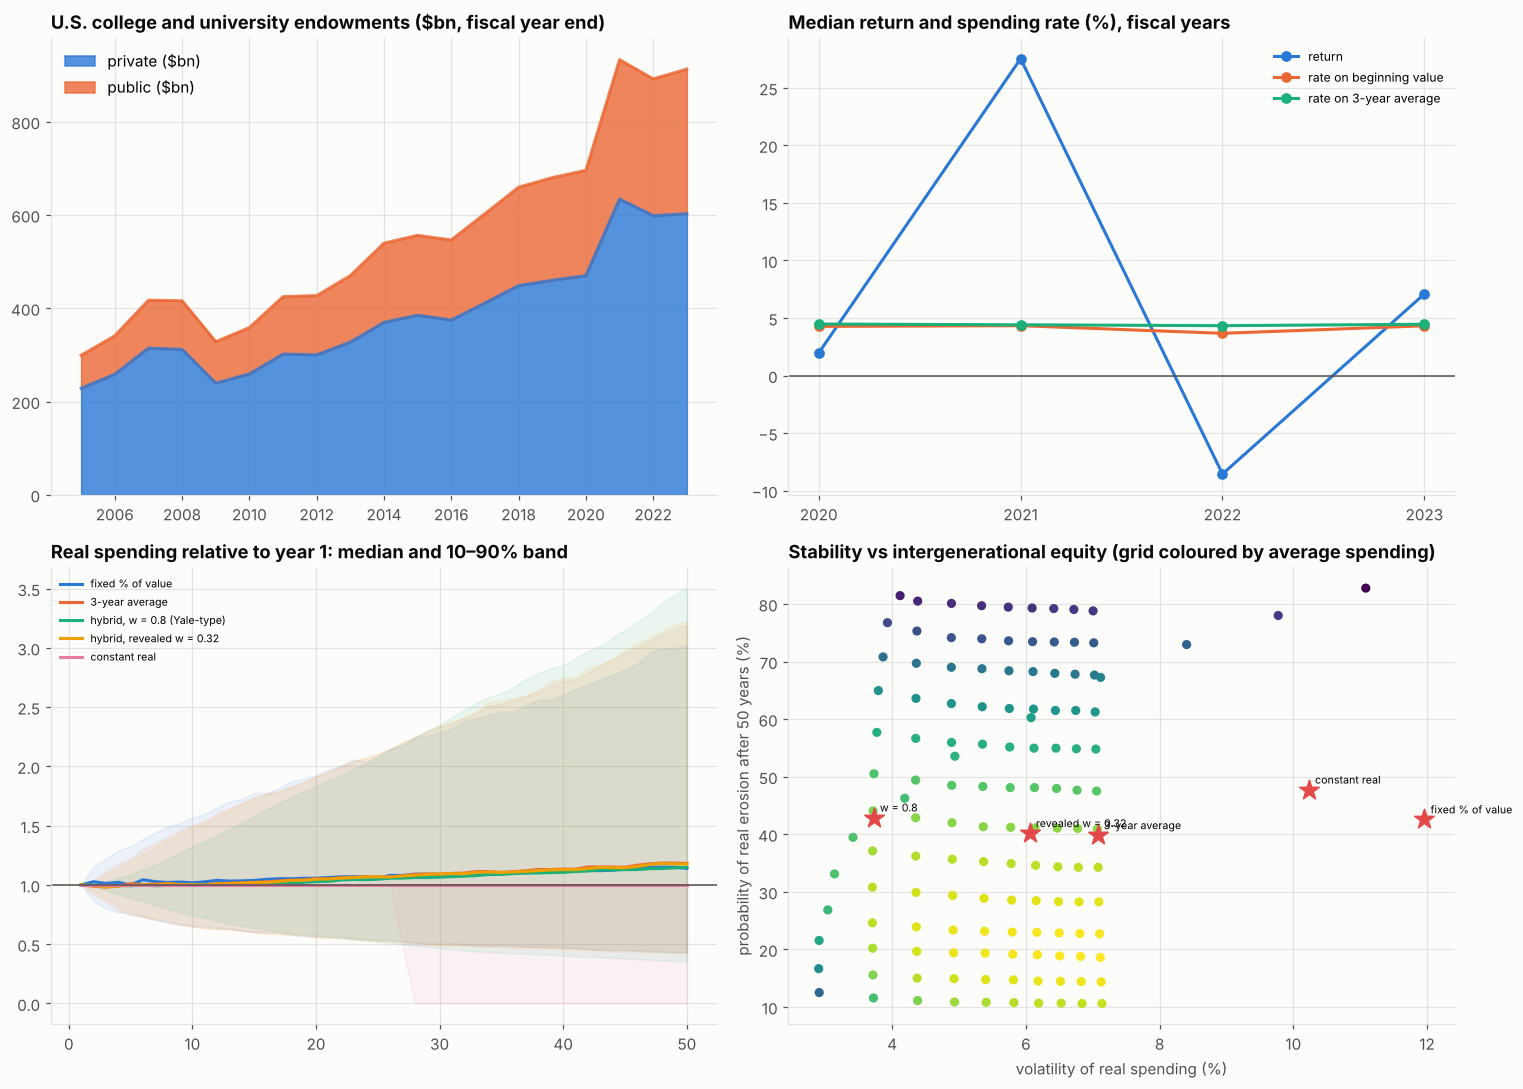

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
MARKET[["private ($bn)", "public ($bn)"]].plot.area(
    ax=a, color=PALETTE[:2], alpha=0.8
)
a.set_xlabel("")
a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
a.set_title("U.S. college and university endowments ($bn, fiscal year end)")
a = ax[0, 1]
for c, col in zip(
    ["return", "rate on beginning value", "rate on 3-year average"], PALETTE
):
    a.plot(BY_YEAR.index, BY_YEAR[c] * 100, marker="o", color=col, label=c)
a.axhline(0, color=INK_2, lw=1)
a.set_xticks(BY_YEAR.index)
a.set_title("Median return and spending rate (%), fiscal years")
a.legend(fontsize=8)
a = ax[1, 0]
for (name, (sp, va)), col in zip(SIM.items(), PALETTE):
    a.plot(
        np.arange(1, HORIZON + 1),
        np.median(sp / sp[:, [0]], axis=0),
        color=col,
        label=name,
    )
    a.fill_between(
        np.arange(1, HORIZON + 1),
        *np.percentile(sp / sp[:, [0]], [10, 90], axis=0),
        color=col,
        alpha=0.08
    )
a.axhline(1, color=INK_2, lw=1)
a.set_title("Real spending relative to year 1: median and 10–90% band")
a.legend(fontsize=7)
a = ax[1, 1]
a.scatter(
    GRID["volatility of real spending"] * 100,
    GRID["P(real value after 50y < start)"] * 100,
    c=GRID["average real spending"],
    cmap="viridis",
    s=25,
)
for name, row in RULE_TABLE.iterrows():
    a.scatter(
        row["volatility of real spending"] * 100,
        row["P(real value after 50y < start)"] * 100,
        marker="*",
        s=180,
        color=STATUS["red"],
    )
    a.annotate(
        name.replace("hybrid, ", "").replace(" (Yale-type)", ""),
        (
            row["volatility of real spending"] * 100,
            row["P(real value after 50y < start)"] * 100,
        ),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points",
    )
a.set_xlabel("volatility of real spending (%)")
a.set_ylabel("probability of real erosion after 50 years (%)")
a.set_title(
    "Stability vs intergenerational equity (grid coloured by average spending)"
)
fig.tight_layout()
save_fig(fig, "01_endowment_spending")
plt.show()

In [11]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Median spending rate by endowment size (on beginning value, %)",
        "Revealed smoothing weight by group",
        "Spending forecast error, fiscal 2023 (MAE, pp)",
        "Real endowment value after 50 years: distribution by rule",
    ),
)
for s, col in zip(BY_SIZE["rate on beginning value"].columns, PALETTE):
    dash.add_trace(
        go.Scatter(
            x=BY_SIZE.index,
            y=BY_SIZE["rate on beginning value"][s] * 100,
            name=str(s),
            line_color=col,
        ),
        1,
        1,
    )
dash.add_trace(
    go.Bar(
        x=REVEALED.index,
        y=REVEALED["smoothing weight w"],
        name="w",
        marker_color=PALETTE[1],
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=FORECAST.index,
        y=FORECAST["MAE (pp)"],
        name="MAE",
        marker_color=PALETTE[2],
    ),
    2,
    1,
)
for (name, (sp, va)), col in zip(SIM.items(), PALETTE):
    dash.add_trace(
        go.Box(
            y=va[:, -1],
            name=name.split(",")[0],
            marker_color=col,
            boxpoints=False,
        ),
        2,
        2,
    )
dash.update_layout(
    height=950,
    width=1400,
    template="simple_white",
    showlegend=False,
    title=(
        "Endowment spending rules: what institutions do and what history says"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**The market.** U.S. college and university endowments reported in IPEDS grew from \$299 billion in fiscal 2005 to \$913 billion in fiscal 2023, held by 2,645 institutions. Private institutions hold two thirds. The market is concentrated: the 20 largest endowments hold 46% of the total, a share that has not changed in two decades. The five largest in fiscal 2023 were Harvard (\$50.7bn), the University of Texas System (\$43.9bn), Yale (\$40.7bn), Stanford (\$36.5bn) and Princeton (\$33.4bn). Total assets fell 21% in fiscal 2009 and rose 34% in fiscal 2021, the best year on record.

**Spending is smoother than returns.** Median figures for endowments above \$10 million:

| Fiscal year | Return | Spending / beginning value | Spending / 3-year average | New gifts / beginning value |
|---|---|---|---|---|
| 2020 | +2.0% | 4.27% | 4.47% | 2.3% |
| 2021 | +27.5% | 4.33% | 4.41% | 2.6% |
| 2022 | −8.6% | 3.67% | 4.33% | 2.6% |
| 2023 | +7.1% | 4.32% | 4.46% | 2.3% |

On the three-year average, the median spending rate stayed between 4.3% and 4.5% while returns swung from +27.5% to −8.6%. That is what the moving-average rule is designed to do. The largest endowments earned the most in 2021 (+35.7% against +26.0% for those under \$100 million) and lost the least in 2022 (−4.6% against −10.1%). Their private equity and venture holdings are valued with a lag, so they gave back part of the difference in 2023 (+4.1% against +7.9%). About 10% of institution-years spent more than 7% of the beginning value, the level UPMIFA presumes imprudent (UPMIFA applies it to a three-year average, so a single year above 7% is not by itself a breach); four in five of them are funds under \$100 million.

**The revealed rule.** Pooled over 2021–2023, a robust regression of spending on last year's spending grown with inflation and on the three-year average gives:
- a smoothing weight of 0.32 on last year's spending and a long-run rate of 4.5% on the three-year average;
- private institutions 0.29 and 4.7%, public institutions 0.35 and 4.2%;
- endowments above \$1 billion 0.79 and 4.8%, close to the Yale-type hybrid that many large universities publish.

The weight is not stable from year to year (0.34 in 2021, 0.10 in 2022, 0.86 in 2023). After the 2021 boom and the 2022 loss, the three-year average and last year's spending moved apart, and many boards appear to have overridden their formula in one direction or the other. In real terms, median spending fell by 1.6% in 2021 and 1.9% in 2022, because inflation outran the slow-moving average, and rose 6.3% in 2023, when the 2021 gains had entered the three-year average.

**Next year's spending is best predicted by this year's.** Out of time on fiscal 2023:

| Forecast | Mean absolute error | R² | Within 0.5 points |
|---|---|---|---|
| Revealed rule (4.4% × three-year average) | 1.83 pts | 0.00 | 31% |
| Own last rate, grown with inflation | 1.36 pts | 0.22 | 53% |
| Ridge regression | 1.56 pts | 0.25 | 35% |
| LightGBM | 1.42 pts | 0.26 | 43% |

One common rate applied to everyone is the worst forecast: institutions use different rates. The institution's own last spending, grown with inflation, is right within half a point for more than half of them. LightGBM explains slightly more of the variance but has a larger typical error, because a minority of institutions with large transfers or one-off distributions dominate the errors.

**Fifty years of spending.** The 60/20/10/10 portfolio earned 8.9% a year nominal and 5.8% real on average since 1928, after 0.5% of costs. Starting from 4.5% of the endowment:

| Rule | Average real spending (per 100 today) | Volatility of real spending | Years with a real cut > 10% | P(real value after 50 years < today) | P(fund exhausted) |
|---|---|---|---|---|---|
| Fixed % of value | 5.58 | 12.0% | 17.1% | 43% | 0% |
| 3-year average | 5.61 | 7.1% | 8.5% | 40% | 0% |
| Hybrid, w = 0.8 (Yale-type) | 5.58 | 3.7% | 0.1% | 43% | 0% |
| Hybrid, revealed w = 0.32 | 5.61 | 6.1% | 5.5% | 40% | 0% |
| Constant real | 3.94 | 10.2% | 1.4% | 48% | 35% |

- **Smoothing is almost free.** All three market-linked rules spend about the same on average over 50 years and leave about the same endowment. The difference is how spending gets there: the fixed percentage cuts real spending by more than 10% in one year out of six, the three-year average in one year out of twelve, and the Yale-type hybrid almost never.
- **Constant real spending is the dangerous rule.** Without a link to market value, it exhausts the fund in 35% of paths and spends less on average, because exhausted funds spend nothing.
- **The rate, not the formula, decides intergenerational equity.** At 4.5%, the real value after 50 years falls below today's in about 40% of paths. The probability is 28% at 4%, 19% at 3.5% and 11% at 3%, but 55% at 5% and 79% at 6%. Average real spending over 50 years barely changes between 3% and 4.5% (5.6–5.7 per 100), because a lower rate leaves a larger fund to spend from later. It falls only above 4.5%.
- **The best rule found.** Under the constraints of at most a 50% chance of real erosion and at most 5% of years with a real cut above 10%, the grid search picks a hybrid with w = 0.3 and a 3.5% rate. It gives the highest average real spending, 5.71 per 100, with a 19% chance of erosion. A smoothing weight of 0.5–0.8 removes almost all large real cuts at a small cost in average spending.

**History is harsher than the average.** In the actual sequences:
- **1929 start:** every market-linked rule ended 50 years later with about half its real value (42–50 per 100).
- **1966 start:** they ended with 70–85; inflation in the 1970s eroded bonds and stocks together.
- **2000 start:** after 26 years they were still at 81–89.

Constant real spending exhausted the fund in both the 1929 and 1966 replays and was down to 22 by 2025 after starting in 2000. The Yale-type hybrid kept spending smoothest in every replay, but because it adjusts slowly it ended with the lowest real value of the market-linked rules.

**What this means for endowment managers.**
- The choice of smoothing (fixed percentage, moving average or hybrid) is a choice about the stability of the operating budget, not about long-run spending: the averages are almost identical.
- Intergenerational equity depends on the spending rate relative to the real return after costs. With a diversified portfolio of public assets, 4.5% leaves roughly even odds of preserving purchasing power over 50 years without new gifts, and gifts of about 2.5% a year are what keeps most endowments growing.
- Spending is sticky. In budgeting, the institution's own last spending grown with inflation is a better guide than a market-wide formula or a model.

**Limitations.**
- **IPEDS:** endowment values are self-reported, institutions may report a system or a foundation differently from year to year, and the flow detail starts only in fiscal 2020. Endowments held by a separate foundation outside the institution's statements can be missing or understated, especially at public universities.
- **Returns:** the simulated portfolio holds public-market indices, not the private equity, hedge funds and real assets of large endowments, and the costs of 0.5% a year are an assumption. Inflation is CPI rather than the higher Higher Education Price Index, so real erosion is if anything understated.
- **Simulation:** five-year blocks from 98 years of history give limited independent information about the worst decades; gifts and special distributions are left out.
- **Revealed rule:** the three-year average uses fiscal year-end values, while most rules use 12 or 20 quarters; with only three years of flows per institution, the smoothing weight is estimated from the cross-section and varies a lot by year.

In [12]:
MARKET.to_csv(OUT_DIR / "endowment_market_by_year.csv")
BY_YEAR.to_csv(OUT_DIR / "returns_spending_by_year.csv")
BY_SIZE.to_csv(OUT_DIR / "returns_spending_by_size.csv")
REVEALED.to_csv(OUT_DIR / "revealed_spending_rule.csv")
FORECAST.to_csv(OUT_DIR / "spending_forecast_2023.csv")
RULE_TABLE.to_csv(OUT_DIR / "spending_rules_simulation.csv")
GRID.to_csv(OUT_DIR / "hybrid_rule_grid.csv", index=False)
REPLAY.to_csv(OUT_DIR / "historical_replays.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_endowment_spending.png, dashboard.html, dashboard.png, endowment_market_by_year.csv, historical_replays.csv, hybrid_rule_grid.csv, returns_spending_by_size.csv, returns_spending_by_year.csv, revealed_spending_rule.csv, spending_forecast_2023.csv, spending_rules_simulation.csv


## References

### Endowments, spending and data

- Tobin, J. (1974). What is permanent endowment income? *The American Economic Review, 64*(2), 427–432.
- Brown, J. R., Dimmock, S. G., Kang, J.-K., & Weisbenner, S. J. (2014). How university endowments respond to financial market shocks: Evidence and implications. *American Economic Review, 104*(3), 931–962. https://doi.org/10.1257/aer.104.3.931
- Lerner, J., Schoar, A., & Wang, J. (2008). Secrets of the academy: The drivers of university endowment success. *Journal of Economic Perspectives, 22*(3), 207–222. https://doi.org/10.1257/jep.22.3.207
- Dybvig, P. H. (1995). Dusenberry's ratcheting of consumption: Optimal dynamic consumption and investment given intolerance for any decline in standard of living. *The Review of Economic Studies, 62*(2), 287–313. https://doi.org/10.2307/2297806
- National Center for Education Statistics. (2026). *Integrated Postsecondary Education Data System (IPEDS): Finance survey and institutional characteristics* [Data set]. U.S. Department of Education. https://nces.ed.gov/ipeds/datacenter/DataFiles.aspx
- Damodaran, A. (2026). *Historical returns on stocks, bonds and bills: 1928–2025* [Data set]. NYU Stern School of Business. https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/histret.html

### Statistics and machine learning

- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics, 17*(3), 1217–1241. https://doi.org/10.1214/aos/1176347265
- Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics, 35*(1), 73–101. https://doi.org/10.1214/aoms/1177703732
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html